<h1> Milestone 3 - Workshop </h1>

What needs to get done

- Analysis of the target variable (check to see if we already have it)
- Table of all the model performances

In [3]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [4]:
#Removing Frame
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.bottom'] = True

<h3> What needs to be done </h3>

We have 2 datasets from our section of Aviation System Performance that we want to examine for our airline departure delay problem: Can we find the factors that exhibit the most significant impact on a flight NOT operating on schedule? Examining weather-related and non weather-related delay factors.

- 2015 Flight Delay + Cancellations Dataset: https://www.kaggle.com/datasets/usdot/flight-delays
- 2019 H1 Flight Delay + Causes Dataset: https://www.kaggle.com/datasets/undersc0re/flight-delay-and-causes
  
For each dataset (after preprocessing steps), we want to:

- Multivariate Analysis (heatmaps, PCA, bubble plots, linear regression)
- Run a Random Forest Model with the Data
  
These will fuel our conclusions:

- How do these analyses compare to the analysis from Milestone 3? (Univariate/Bivariate Analysis vs. Multivariate Analysis and random forest)
- For above, do we see any new relationships with the target variable?
- What aspects of the data were unexpected?
- The final capstone proposal
  
Some other helpful guidelines:

You should include 6-8 figures/graphs in the body of the paper (size-wise, a single page should fit 6 figures), so be sure to generate as much as you can first then scale down

<h3> Dataset Downloads </h3>

In [8]:
d19 = pd.read_csv('Flight_delay_2019H1.csv', low_memory = False)
d19.info()

<class 'pandas.DataFrame'>
RangeIndex: 484551 entries, 0 to 484550
Data columns (total 29 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   DayOfWeek          484551 non-null  int64
 1   Date               484551 non-null  str  
 2   DepTime            484551 non-null  int64
 3   ArrTime            484551 non-null  int64
 4   CRSArrTime         484551 non-null  int64
 5   UniqueCarrier      484551 non-null  str  
 6   Airline            484551 non-null  str  
 7   FlightNum          484551 non-null  int64
 8   TailNum            484551 non-null  str  
 9   ActualElapsedTime  484551 non-null  int64
 10  CRSElapsedTime     484551 non-null  int64
 11  AirTime            484551 non-null  int64
 12  ArrDelay           484551 non-null  int64
 13  DepDelay           484551 non-null  int64
 14  Origin             484551 non-null  str  
 15  Org_Airport        483374 non-null  str  
 16  Dest               484551 non-null  str  
 17  De

In [9]:
d19.describe()

,DayOfWeek,DepTime,ArrTime,CRSArrTime,FlightNum,ActualElapsedTime,CRSElapsedTime,AirTime,ArrDelay,DepDelay,Distance,TaxiIn,TaxiOut,Cancelled,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
count,484551.000000,484551.000000,484551.000000,484551.000000,484551.000000,484551.000000,484551.000000,484551.000000,484551.000000,484551.000000,484551.000000,484551.000000,484551.000000,484551.0,484551.0,484551.000000,484551.000000,484551.000000,484551.000000,484551.000000
mean,3.991605,1564.477865,1617.784438,1652.129929,2139.207386,134.810422,131.400761,108.877134,60.907764,57.498086,752.142689,6.782413,19.150876,0.0,0.0,17.419440,3.153284,13.599421,0.082033,26.653587
std,1.971466,452.235219,583.637660,466.096216,1812.677071,74.070374,71.542531,70.113513,56.975420,55.991012,571.631124,5.555816,15.309747,0.0,0.0,39.417893,19.503657,31.454655,1.884774,40.535994
min,1.000000,1.000000,1.000000,1.000000,1.000000,15.000000,-21.000000,0.000000,15.000000,6.000000,31.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,1234.000000,1327.000000,1339.000000,629.000000,80.000000,79.000000,57.000000,25.000000,23.000000,331.000000,4.000000,11.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
50%,4.000000,1620.000000,1737.000000,1723.000000,1514.000000,116.000000,114.000000,90.000000,42.000000,40.000000,599.000000,5.000000,15.000000,0.0,0.0,2.000000,0.000000,1.000000,0.000000,13.000000
75%,6.000000,1928.000000,2049.000000,2025.000000,3683.000000,168.000000,162.000000,139.000000,76.000000,72.000000,992.000000,8.000000,22.000000,0.0,0.0,19.000000,0.000000,13.000000,0.000000,36.000000
max,7.000000,2400.000000,2400.000000,2359.000000,8403.000000,727.000000,602.000000,609.000000,1707.000000,1710.000000,4502.000000,207.000000,383.000000,0.0,0.0,1707.000000,1148.000000,1357.000000,392.000000,1254.000000


<h2> Dataset: 2019 Flight Delays and Causes</h2>

<h3>Data Dictionary</h3>

- DayOfWeek → 1 (Monday) - 7 (Sunday)
- Date → Scheduled date
- DepTime → Actual departure time (local, hhmm)
- ArrTime → Actual arrival time (local, hhmm)
- CRSArrTime → Scheduled arrival time (local, hhmm)
- UniqueCarrier → Unique carrier code
- Airline → Airline company
- FlightNum → flight number
- TailNum → plane tail number
- ActualElapsedTime → Actual time an airplane spends in the air(in minutes) with TaxiIn/Out
- CRSElapsedTime → CRS Elapsed Time of Flight (estimated elapse time), in minutes
- AirTime → Flight Time (in minutes)
- ArrDelay → Difference in minutes between scheduled and actual arrival time
- Origin → Origin IATA(International Air Transport Association) airport code
- Org_Airport → Origin Airport Name
- Dest → Destination IATA code
- Dest_Airport → Destination Airport Name
- Distance → Distance between airports (miles)
- TaxiIn → Wheels down and arrival at the destination airport gate, in minutes
- TaxiOut → The time elapsed between departure from the origin airport gate and wheels off, in minutes
- Cancelled → Was the flight canceled?
- CancellationCode → Reason for cancellation
- Diverted → 1 = yes, 0 = no
- CarrierDelay → Flight delay due to carrier(e.g. maintenance or crew problems, aircraft cleaning, fueling, etc), 0 = No, yes = (in minutes)
- WeatherDelay → Flight delay due to weather, 0 = No, yes = (in minutes)
- NASDelay → Flight delay by NSA(National Aviation System), 0 = No, yes = (in minutes)
- SecurityDelay → Flight delay by this reason, 0 = No, yes = (in minutes)
- LateAircraftDelay → Flight delay by this reason, 0 = No, yes = (in minutes)

In [13]:
all19 = d19.copy()

<h3> Preprocessing </h3>

In [15]:
all19.head()

,DayOfWeek,Date,DepTime,ArrTime,CRSArrTime,UniqueCarrier,Airline,FlightNum,TailNum,ActualElapsedTime,...,TaxiIn,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,4,03-01-2019,1829,1959,1925,WN,Southwest Airlines Co.,3920,N464WN,90,...,3,10,0,N,0,2,0,0,0,32
1,4,03-01-2019,1937,2037,1940,WN,Southwest Airlines Co.,509,N763SW,240,...,3,7,0,N,0,10,0,0,0,47
2,4,03-01-2019,1644,1845,1725,WN,Southwest Airlines Co.,1333,N334SW,121,...,6,8,0,N,0,8,0,0,0,72
3,4,03-01-2019,1452,1640,1625,WN,Southwest Airlines Co.,675,N286WN,228,...,7,8,0,N,0,3,0,0,0,12
4,4,03-01-2019,1323,1526,1510,WN,Southwest Airlines Co.,4,N674AA,123,...,4,9,0,N,0,0,0,0,0,16


In [16]:
all19.info()

<class 'pandas.DataFrame'>
RangeIndex: 484551 entries, 0 to 484550
Data columns (total 29 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   DayOfWeek          484551 non-null  int64
 1   Date               484551 non-null  str  
 2   DepTime            484551 non-null  int64
 3   ArrTime            484551 non-null  int64
 4   CRSArrTime         484551 non-null  int64
 5   UniqueCarrier      484551 non-null  str  
 6   Airline            484551 non-null  str  
 7   FlightNum          484551 non-null  int64
 8   TailNum            484551 non-null  str  
 9   ActualElapsedTime  484551 non-null  int64
 10  CRSElapsedTime     484551 non-null  int64
 11  AirTime            484551 non-null  int64
 12  ArrDelay           484551 non-null  int64
 13  DepDelay           484551 non-null  int64
 14  Origin             484551 non-null  str  
 15  Org_Airport        483374 non-null  str  
 16  Dest               484551 non-null  str  
 17  De

In [17]:
(484551 - 481895)/484551

0.005481363158883173

<h3> Duplicate Rows, Missing Values</h3>

In [19]:
dupes_19 = all19[all19.duplicated()]
dupes_19

,DayOfWeek,Date,DepTime,ArrTime,CRSArrTime,UniqueCarrier,Airline,FlightNum,TailNum,ActualElapsedTime,...,TaxiIn,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
145746,4,28-02-2019,1854,1946,1902,F9,Frontier Airlines Inc.,773,N201FR,112,...,8,13,0,N,0,44,0,0,0,0
145748,4,28-02-2019,2027,2314,2229,F9,Frontier Airlines Inc.,780,N201FR,107,...,10,13,0,N,0,1,0,44,0,0


In [20]:
#get rid of the null origin/destination airport values

f19 = all19.dropna()

In [21]:
f19.info()

<class 'pandas.DataFrame'>
Index: 481895 entries, 0 to 484550
Data columns (total 29 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   DayOfWeek          481895 non-null  int64
 1   Date               481895 non-null  str  
 2   DepTime            481895 non-null  int64
 3   ArrTime            481895 non-null  int64
 4   CRSArrTime         481895 non-null  int64
 5   UniqueCarrier      481895 non-null  str  
 6   Airline            481895 non-null  str  
 7   FlightNum          481895 non-null  int64
 8   TailNum            481895 non-null  str  
 9   ActualElapsedTime  481895 non-null  int64
 10  CRSElapsedTime     481895 non-null  int64
 11  AirTime            481895 non-null  int64
 12  ArrDelay           481895 non-null  int64
 13  DepDelay           481895 non-null  int64
 14  Origin             481895 non-null  str  
 15  Org_Airport        481895 non-null  str  
 16  Dest               481895 non-null  str  
 17  Dest_Ai

<h3> Creating TotalDelay Column </h3>

In [23]:
f19['TotalDelay'] = all19.ActualElapsedTime - all19.CRSElapsedTime

In [24]:
f19.head()

,DayOfWeek,Date,DepTime,ArrTime,CRSArrTime,UniqueCarrier,Airline,FlightNum,TailNum,ActualElapsedTime,...,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay,TotalDelay
0,4,03-01-2019,1829,1959,1925,WN,Southwest Airlines Co.,3920,N464WN,90,...,10,0,N,0,2,0,0,0,32,0
1,4,03-01-2019,1937,2037,1940,WN,Southwest Airlines Co.,509,N763SW,240,...,7,0,N,0,10,0,0,0,47,-10
2,4,03-01-2019,1644,1845,1725,WN,Southwest Airlines Co.,1333,N334SW,121,...,8,0,N,0,8,0,0,0,72,-14
3,4,03-01-2019,1452,1640,1625,WN,Southwest Airlines Co.,675,N286WN,228,...,8,0,N,0,3,0,0,0,12,-12
4,4,03-01-2019,1323,1526,1510,WN,Southwest Airlines Co.,4,N674AA,123,...,9,0,N,0,0,0,0,0,16,-12


In [25]:
f19.Cancelled.value_counts()

Cancelled
0    481895
Name: count, dtype: int64

In [26]:
f19 = f19.drop(['Cancelled', 'CancellationCode'], axis = 1)

First preprocessing steps:

- Created TotalDelay column
- There are no cancelled flights in this dataset
- Dropped null values (no origin/destination airport)

Final dataset size: 481,895 rows

<h3> Adjusting the Date Variables </h3>

In [29]:
f19['Date'] = pd.to_datetime(f19['Date'], format = '%d-%m-%Y')

In [30]:
f19.head()

,DayOfWeek,Date,DepTime,ArrTime,CRSArrTime,UniqueCarrier,Airline,FlightNum,TailNum,ActualElapsedTime,...,Distance,TaxiIn,TaxiOut,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay,TotalDelay
0,4,2019-01-03,1829,1959,1925,WN,Southwest Airlines Co.,3920,N464WN,90,...,515,3,10,0,2,0,0,0,32,0
1,4,2019-01-03,1937,2037,1940,WN,Southwest Airlines Co.,509,N763SW,240,...,1591,3,7,0,10,0,0,0,47,-10
2,4,2019-01-03,1644,1845,1725,WN,Southwest Airlines Co.,1333,N334SW,121,...,828,6,8,0,8,0,0,0,72,-14
3,4,2019-01-03,1452,1640,1625,WN,Southwest Airlines Co.,675,N286WN,228,...,1489,7,8,0,3,0,0,0,12,-12
4,4,2019-01-03,1323,1526,1510,WN,Southwest Airlines Co.,4,N674AA,123,...,838,4,9,0,0,0,0,0,16,-12


Second set of preprocessing steps:

- Changed Date variable to timestamp

<h3>EDA - Multivariate</h3>

In [33]:
number19 = f19.select_dtypes(include=np.number).drop(['Diverted', 'TotalDelay', 'ArrTime', 'DepTime', 'FlightNum', 'CRSArrTime'], axis = 1) #creating df of numeric columns only to run correlation matrix
corrs = number19.corr()

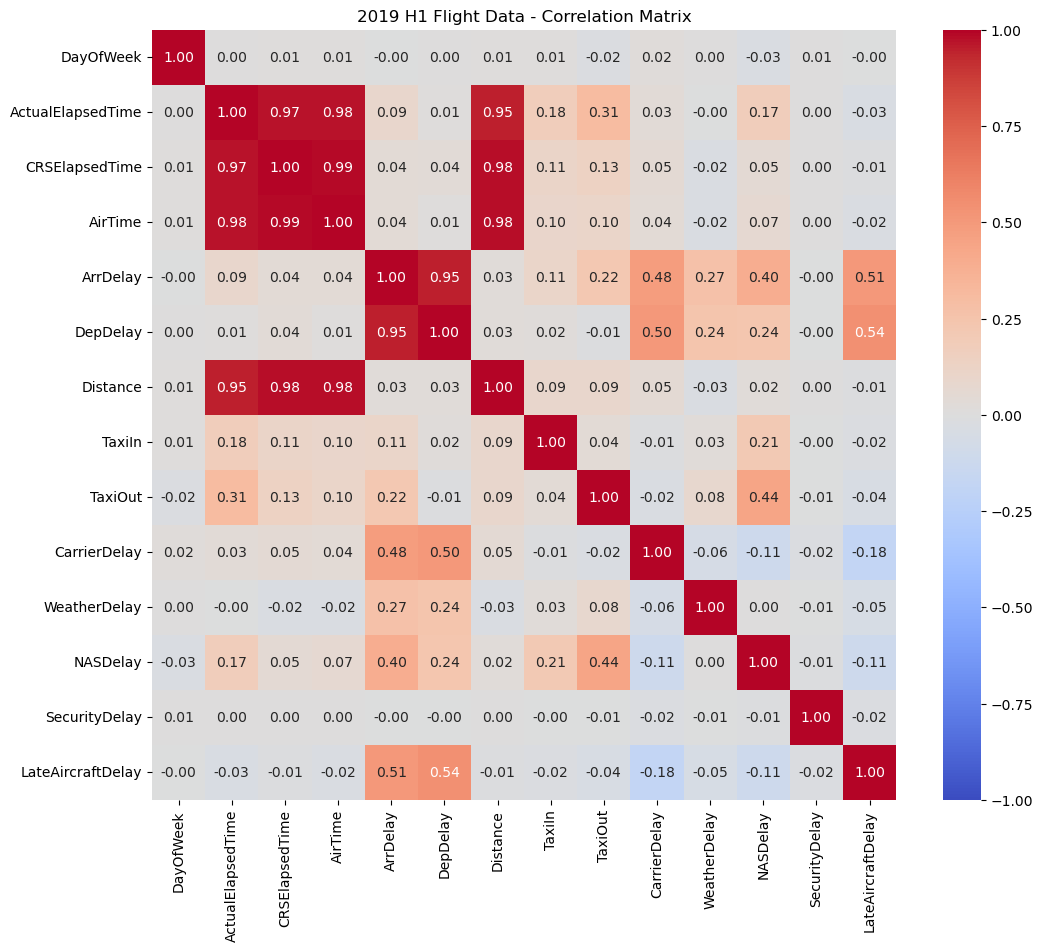

In [34]:
# correlation matrix for reference
plt.figure(figsize=(12, 10))

# Making a heatmap
sns.heatmap(corrs,
            annot=True,     # Annotate each cell with the correlation value
            fmt=".2f",      # Set the annotation format to two decimal places
            cmap='coolwarm',# Choose a divergent color map
            vmin=-1, vmax=1,# Ensure the color scale ranges from -1 to 1
            center=0        # Center the color map at 0
           )

# Display the plot
plt.title('2019 H1 Flight Data - Correlation Matrix')
plt.show()

<h3>Heatmaps</h3>

In [57]:
pivot1 = f19.pivot_table(index = ["Airline"], columns = ["DayOfWeek"], values = "DepDelay", aggfunc = "mean")

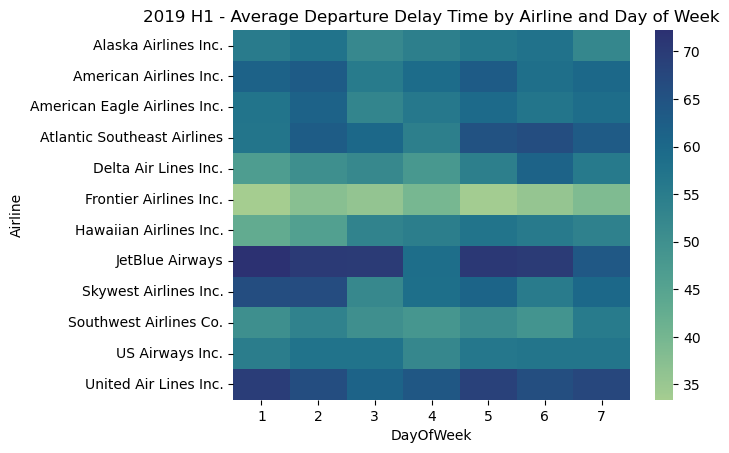

In [119]:
ax1 = sns.heatmap(pivot1, cmap = "crest")
ax1.set_title("2019 H1 - Average Departure Delay Time by Airline and Day of Week");

In [63]:
pivot2 = f19.pivot_table(index = ["Airline"], columns = ["DayOfWeek"], values = "TotalDelay", aggfunc = "mean")

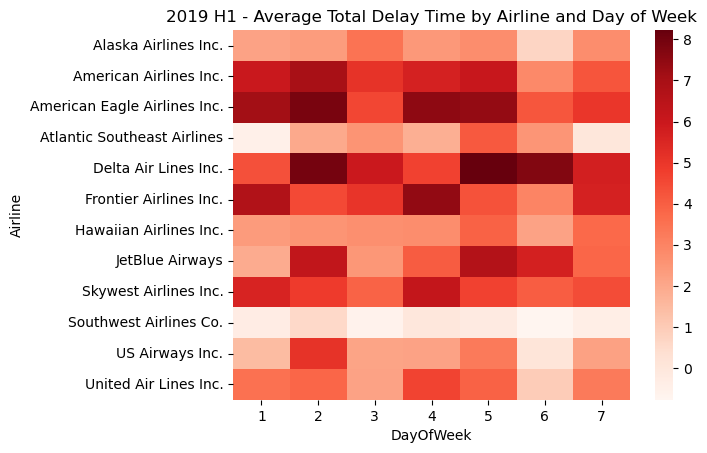

In [115]:
ax2 = sns.heatmap(pivot2, cmap = "Reds")
ax2.set_title("2019 H1 - Average Total Delay Time by Airline and Day of Week");

<h3>Bubble Plots</h3>

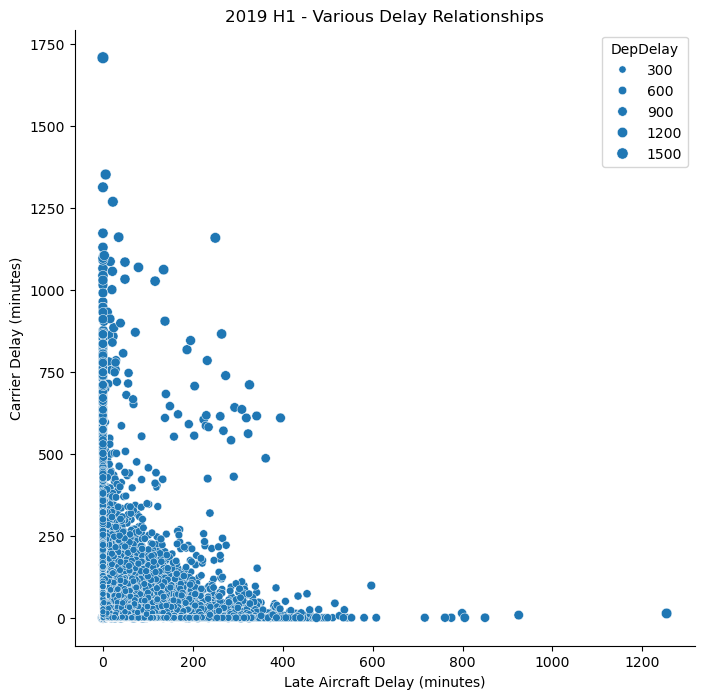

In [70]:
plt.figure(figsize=(8, 8))
ax2 = sns.scatterplot(data = f19, x = "LateAircraftDelay", y = "CarrierDelay", size = "DepDelay")
ax2.set_xlabel("Late Aircraft Delay (minutes)")
ax2.set_ylabel("Carrier Delay (minutes)")
ax2.set_title('2019 H1 - Various Delay Relationships')
plt.show();

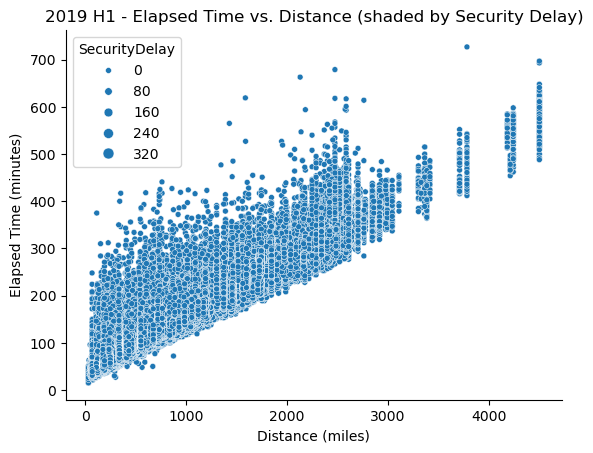

In [72]:
ax3 = sns.scatterplot(data = f19, x = "Distance", y = "ActualElapsedTime", size = "SecurityDelay")
ax3.set_xlabel("Distance (miles)")
ax3.set_ylabel("Elapsed Time (minutes)")
ax3.set_title('2019 H1 - Elapsed Time vs. Distance (shaded by Security Delay)')
plt.show();

<h3>PCA</h3>

In [75]:
from sklearn.decomposition import PCA

In [77]:
pca = PCA(n_components = 3)
pca.fit(number19)
print('Explained variance ratios of', len(pca.components_), 'principal components:', pca.explained_variance_ratio_)
print()
print(pca.components_)

Explained variance ratios of 3 principal components: [0.75584938 0.11853914 0.06639381]

[[-1.42277428e-05 -7.40707943e-03  2.40822234e-03 -1.63923493e-02
   9.91533134e-01 -1.48153352e-02 -1.51221756e-02 -1.48417220e-02
   7.27065471e-04  4.20233425e-04 -1.25938476e-01  1.29380566e-05
   1.34488228e-05  6.77784646e-04  6.72117640e-04  6.42211291e-04
  -1.37127105e-06 -1.26367684e-03  3.06840446e-04]
 [ 3.84262832e-05  4.72238792e-01  6.86118228e-01  5.43226653e-01
  -2.79457947e-03 -1.23548309e-02 -1.13712405e-02 -1.18358140e-02
  -4.82739938e-05  9.35332952e-04 -1.03225803e-01 -4.96973646e-05
  -4.69319550e-04 -4.99264419e-03 -5.15035057e-04  5.96461015e-04
  -4.37631182e-05  4.90670736e-03 -9.83590389e-04]
 [ 3.38095773e-05  1.02386459e-02  6.68466580e-02  9.80881716e-02
   1.29159717e-01  1.20148011e-01  1.19554662e-01  1.16172677e-01
   4.43491558e-03  3.84157354e-03  9.62718047e-01  1.05098700e-03
   2.92434674e-03  3.94131252e-03 -2.24594071e-04  2.79957645e-03
  -1.79090690e-06

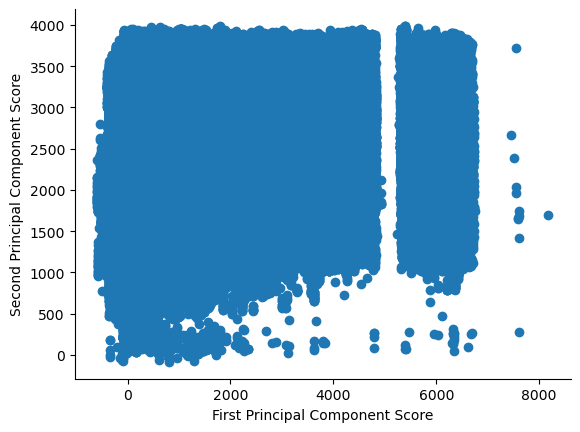

In [79]:
first_principal_component_score = number19.dot(pca.components_[0])
second_principal_component_score = number19.dot(pca.components_[1])
plt.scatter(first_principal_component_score, second_principal_component_score)
plt.xlabel("First Principal Component Score")
plt.ylabel("Second Principal Component Score");

<h3>Linear Regression</h3>

In [82]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, root_mean_squared_error

In [88]:
#standard scaling the numerical data

sc = StandardScaler()

sc19 = sc.fit_transform(number19)
df_scaled = pd.DataFrame(sc19, columns=number19.columns)
df_scaled.head()

,DayOfWeek,DepTime,ArrTime,CRSArrTime,FlightNum,ActualElapsedTime,CRSElapsedTime,AirTime,ArrDelay,DepDelay,Distance,TaxiIn,TaxiOut,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay,TotalDelay
0,0.004507,0.584211,0.583753,0.583732,0.996963,-0.609590,-0.583439,-0.459369,-0.471963,-0.419299,-0.419948,-0.681238,-0.597744,-0.390382,-0.161092,-0.432646,-0.043374,0.129965,-0.188476
1,0.004507,0.822991,0.717269,0.615905,-0.894996,1.414908,1.652383,1.722125,-0.068092,0.170411,1.462134,-0.681238,-0.793451,-0.186718,-0.161092,-0.432646,-0.043374,0.499698,-0.740563
2,0.004507,0.175189,0.388614,0.154751,-0.437953,-0.191194,0.045386,-0.031625,0.335779,0.652901,0.127535,-0.141305,-0.728215,-0.237634,-0.161092,-0.432646,-0.043374,1.115921,-0.961398
3,0.004507,-0.249309,0.037707,-0.059740,-0.802922,1.252948,1.512644,1.479737,-0.805595,-0.544389,1.283721,0.038673,-0.728215,-0.364924,-0.161092,-0.432646,-0.043374,-0.363013,-0.850981
4,0.004507,-0.534518,-0.157432,-0.306404,-1.175101,-0.164200,0.045386,0.011150,-0.788036,-0.526519,0.145026,-0.501260,-0.662980,-0.441298,-0.161092,-0.432646,-0.043374,-0.264418,-0.850981


In [147]:
#predicting the departure delay time from the different types

delay_types = ['CarrierDelay', 'LateAircraftDelay', 'WeatherDelay', 'SecurityDelay', 'NASDelay']

lr1 = LinearRegression()

lr1.fit(df_scaled[delay_types], df_scaled.DepDelay)

coeff_df1 = pd.Series(lr1.coef_, index=df_scaled[delay_types].columns)
print(coeff_df1)
print()

y_pred1 = lr1.predict(df_scaled[delay_types])
print('RMSE (DepDelay):', root_mean_squared_error(y_pred1, df_scaled.DepDelay))

CarrierDelay         0.702142
LateAircraftDelay    0.732160
WeatherDelay         0.321545
SecurityDelay        0.032398
NASDelay             0.395551
dtype: float64

RMSE (DepDelay): 0.27585658487704734


In [106]:
#predicting the total delay time from the different types

lr2 = LinearRegression()

lr2.fit(df_scaled[delay_types], df_scaled.TotalDelay)

coeff_df2 = pd.Series(lr2.coef_, index=df_scaled[delay_types].columns)
print(coeff_df2)
print()

y_pred2 = lr2.predict(df_scaled[delay_types])
print('RMSE (Total Delay):', root_mean_squared_error(y_pred2, df_scaled.TotalDelay))

CarrierDelay        -0.000621
LateAircraftDelay   -0.022179
WeatherDelay         0.080539
SecurityDelay        0.003740
NASDelay             0.513524
dtype: float64

RMSE (Total Delay): 0.8522491018007251


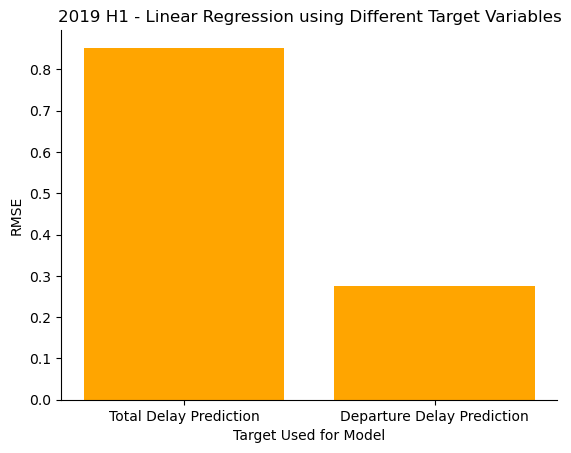

In [112]:
#bar chart of RMSEs
model_types = ['Total Delay Prediction', 'Departure Delay Prediction']
RMSEs = [root_mean_squared_error(y_pred2, df_scaled.TotalDelay), root_mean_squared_error(y_pred1, df_scaled.DepDelay)]

plt.bar(model_types, RMSEs, color = 'Orange')
plt.xlabel('Target Used for Model')
plt.ylabel('RMSE')
plt.title('2019 H1 - Linear Regression using Different Target Variables');

Findings from multivariate analysis (2019 H1):

- The pivot table and subsequent heatmap I was able to create show the average departure delay time by both airline and the day of the week. An interesting finding is that it appears that United Airlines and JetBlue both experience the longest average departure delay times on average regardless of the day of the week (which lines up pretty well with my experience XD), and Frontier Airlines experiencing the least; zooming in a little further, JetBlue experiences the largest average departure delay times on day 1 and 5 (Sunday and Thursday respectively) with days 2, 3, and 6 (Monday, Tuesday, and Friday respectively) not being far behind. IMPORTANT NOTE: Compared to 2015, the scale for the heatmaps are way higher, with the minimum values being around 35 minutes for departure delay and barely on time/0 minutes for total delay. When looking at average total delay times, Southwest appears to have the lowest regardless of day while Delta and American Eagle look to share the highest.
- Running a PCA with 3 components showed that the first principal component covered about 75.5% of the variance in the data, with the second principal component covered about 11.8% more and the third covering about 6% more. Therefore, I think using at least the first two principal components can be an effective way to reduce dimensionality in the data. We needed more components in this dataset than the 2015 which had significantly more data, but still demonstrates dimensionality reduction possibilities.
- Bubble Plot with late aircraft delay on x-axis, airline delay on the y-axis, bubble size is departure delay --> it looks as if the points on the far-right (longer late aircraft delay) and top (high airline delay) have the biggest bubbles, which makes sense. Same trend as 2015
- Linear regressions (using the 5 special delay types, rest of the variables had coefficients close to 0) --> highest positive coefficients for predicting DEPARTURE delay were carrier/airline delay and late aircraft delay (lines up with correlation as well). Highest positive coefficients for predicting TOTAL delay was air system delay with weather wayyyyy behind (also lines up with correlations). Using the same input variables, the RMSE in predicting our created target (total delay) was noticeably larger than the model predicting the existing target variable (departure delay). This tells us that with the same variables, the departure delay prediction (RMSE = 0.276) shows stronger relationships with specific types of delays than the total delay prediction (RMSE = 0.852). This trend is also consistent with the 2015 data

OVERALL Figures to use:

- Heatmap of Average Departure delay times (2019 H1)
- Heatmap of Average TOTAL delay times (2019 H1)
- RMSE Comparison of Linear Regressions (2019 H1)

<h3>Random Forest Model</h3>

In [123]:
#imports
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RepeatedKFold
)

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
random_seed = 42

In [155]:
#set our x_train and y_train (different delay types for X, departure delay time for y)

X_train, X_test, y_train, y_test = train_test_split(df_scaled[delay_types], df_scaled.DepDelay,
                                                    test_size=0.25, random_state=random_seed)

In [157]:
len(X_test)

120474

In [159]:
# Define the model and cross-validation
model = RandomForestRegressor(random_state=random_seed)

repeated_cv = RepeatedKFold(n_splits     = 3, 
                            n_repeats    = 1,
                            random_state = random_seed
                           )     

# Define the parameter grid
param_dist = {
     'n_estimators': np.arange(100, 201, 25)
}

# Use GridSearchCV to find the best parameters

search = GridSearchCV(
    estimator=model,
    param_grid=param_dist,
    scoring='neg_root_mean_squared_error',  # RMSE but negated for maximization by GridSearchCV
    cv= repeated_cv,  # Number of folds for cross-validation -- Reduce this if efficiency is an issue
    n_jobs=-1,
    verbose = 1
)

# Fit the GridSearchCV
search.fit(X_train, y_train)  

# Extract results into a DataFrame
results = pd.DataFrame(search.cv_results_)

# Convert negative RMSE to positive
results['mean_test_RMSE'] = -results['mean_test_score']
results = results.sort_values(by = 'mean_test_RMSE')

# Sort by rank (best scores first)
top_10 = results[[
    'mean_test_RMSE',
    'param_n_estimators'
]].head(10)

# Print the results as a table
print("\nSearch Results (Top 10):\n")
print(top_10)  # Show the top 10 results

Fitting 3 folds for each of 5 candidates, totalling 15 fits

Search Results (Top 10):

   mean_test_RMSE  param_n_estimators
4        0.227038                 200
3        0.227072                 175
2        0.227091                 150
1        0.227178                 125
0        0.227221                 100


In [161]:
#running our best model on the data and generating feature importance

final_model = RandomForestRegressor(n_estimators = 200, random_state=random_seed)

final_model.fit(X_train, y_train)
importances = final_model.feature_importances_

In [163]:
forest_importances = pd.Series(importances, index=delay_types)
f_imp = forest_importances.sort_values(ascending = False)
f_imp

LateAircraftDelay    0.398715
CarrierDelay         0.381304
NASDelay             0.132844
WeatherDelay         0.086377
SecurityDelay        0.000761
dtype: float64

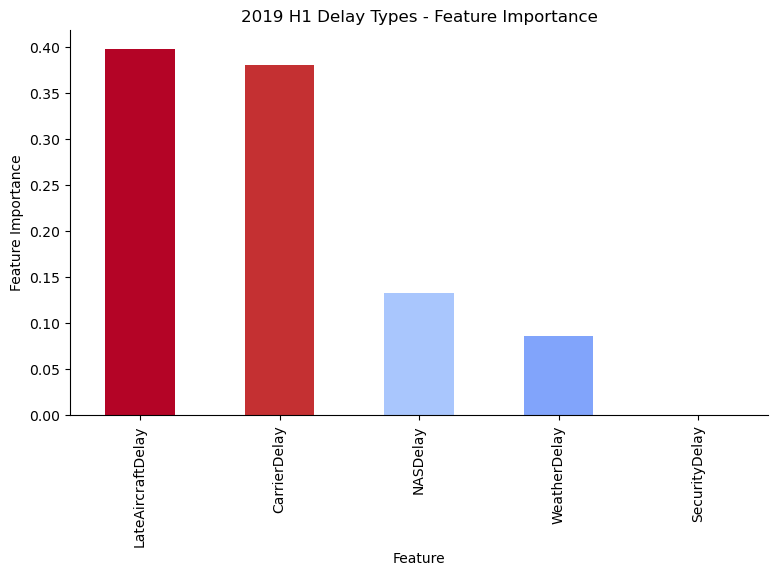

In [165]:
# Generate the bar plot
plt.figure(figsize=(9, 5))
# 1. Normalize values to [0, 1] for the colormap
norm = plt.Normalize(f_imp.min(), f_imp.max())

# 2. Choose a colormap (e.g., 'viridis', 'plasma', 'coolwarm')
cmap = plt.get_cmap('coolwarm')

# 3. Map values to colors
colors = cmap(norm(f_imp))

f_imp.plot.bar(color = colors, title='2019 H1 Delay Types - Feature Importance')
plt.xlabel('Feature')
plt.ylabel('Feature Importance');

In [167]:
y_preds = final_model.predict(X_test)
test_RMSE = root_mean_squared_error(y_test, y_preds)
print('RMSE of our optimized model on the test set:', f"{test_RMSE:.2f}")

RMSE of our optimized model on the test set: 0.22


Findings from Random Forest Model (2015):

- Model we ran was optimized for n_estimators on k-fold cross validation), using the 5 special delay types as input and DepDelay as our target (we're gonna stick with this from here on)
- The two variables with the highest feature importance on a model (test RMSE = 0.22) were LateAircraftDelay and CarrierDelay. Should be noted that the feature importances of the variables our model are in the exact same order as their correlations with the target variable
- RMSE of the RF was slightly better than the regular linear regression, likely due to optimization of the n_estimators hyperparameter
- Order of feature importance holds exactly the same as model we ran on the 2015 data